<a href="https://colab.research.google.com/github/fralfaro/inf449-portafolio/blob/main/tareas/tarea-01/tarea_01.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# Tarea 1: Demosaicking con filtro Bayer

**Objetivo de aprendizaje:** Identificar los filtros que componen un arreglo de filtros Bayer y resolver la tarea de interpolacion o *demosaicking* con algoritmos de interpolacion del estado del arte.

En esta tarea se implementara un sistema basico de fotografia computacional para reconstruir imagenes RGB a partir de una medicion en mosaico generada con un filtro Bayer.

## Enunciado

Implementar un sistema de fotografia computacional en Python para fotografia en color usando el filtro Bayer visto en clase para generar el mosaico o medicion.

A partir del mosaico Bayer, reconstruir la imagen RGB mediante demosaicking usando interpolacion 2D para estimar los valores faltantes de cada canal. En esta tarea se puede utilizar interpolacion bicubica para interpolar los canales rojo, verde y azul.

- Referencia filtro Bayer: <https://en.wikipedia.org/wiki/Bayer_filter>
- Dataset Kodak, 24 imagenes RGB: <https://github.com/MohamedBakrAli/Kodak-Lossless-True-Color-Image-Suite>
- Metricas de calidad:
  - PSNR: <https://www.mathworks.com/help/images/ref/psnr.html>
  - SSIM: <https://www.mathworks.com/help/images/ref/ssim.html>
  - SAM: <https://www.mathworks.com/help/images/ref/sam.html>

Se deben tabular las metricas de calidad para cada imagen y reportar el promedio y la desviacion estandar para todo el dataset.

> **Bonus:** implementar el algoritmo de demosaicking descrito en: <https://web.stanford.edu/class/ee367/reading/Demosaicing_ICASSP04.pdf>

## 1. Preparacion del entorno

Instalar o importar las librerias necesarias. Se recomienda usar `numpy`, `matplotlib`, `scipy`, `scikit-image`, `pandas` y `Pillow`.

In [56]:
# Imports
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from scipy.interpolate import griddata
from scipy.ndimage import uniform_filter,convolve


plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["image.cmap"] = "gray"

## 2. Carga del dataset Kodak

En Google Colab descargaremos el dataset directamente desde GitHub. El repositorio contiene las 24 imagenes RGB dentro de la carpeta `PhotoCD_PCD0992`.

La siguiente celda:

1. Clona el repositorio solo si no existe.
2. Define la ruta `DATASET_DIR`.
3. Busca las imagenes `.png`.
4. Verifica cuantas imagenes fueron encontradas.

> Referencia del dataset: <https://github.com/MohamedBakrAli/Kodak-Lossless-True-Color-Image-Suite/tree/master/PhotoCD_PCD0992>

In [45]:
# Descargar y cargar el dataset Kodak en Google Colab
from pathlib import Path

REPO_URL = "https://github.com/MohamedBakrAli/Kodak-Lossless-True-Color-Image-Suite.git"
REPO_DIR = Path("Kodak-Lossless-True-Color-Image-Suite")

# En Colab, clonar el repositorio si todavia no existe.
# Si ejecutas la celda mas de una vez, no se vuelve a descargar.
if not REPO_DIR.exists():
    !git clone {REPO_URL}

# Carpeta que contiene las 24 imagenes Kodak.
DATASET_DIR = REPO_DIR / "PhotoCD_PCD0992"

# Buscar imagenes PNG del dataset.
image_paths = sorted(DATASET_DIR.glob("*.png"))

print(f"Ruta del dataset: {DATASET_DIR}")
print(f"Imagenes encontradas: {len(image_paths)}")

for path in image_paths:
    print(path.name)

assert len(image_paths) == 24, "No se encontraron las 24 imagenes Kodak. Revisa la descarga o la ruta DATASET_DIR."

Ruta del dataset: Kodak-Lossless-True-Color-Image-Suite/PhotoCD_PCD0992
Imagenes encontradas: 24
01.png
02.png
03.png
04.png
05.png
06.png
07.png
08.png
09.png
10.png
11.png
12.png
13.png
14.png
15.png
16.png
17.png
18.png
19.png
20.png
21.png
22.png
23.png
24.png


Imagen seleccionada: 01.png
Dimensiones: (512, 768, 3)
Valor minimo: 0.0000
Valor maximo: 1.0000
Tipo de dato: float64


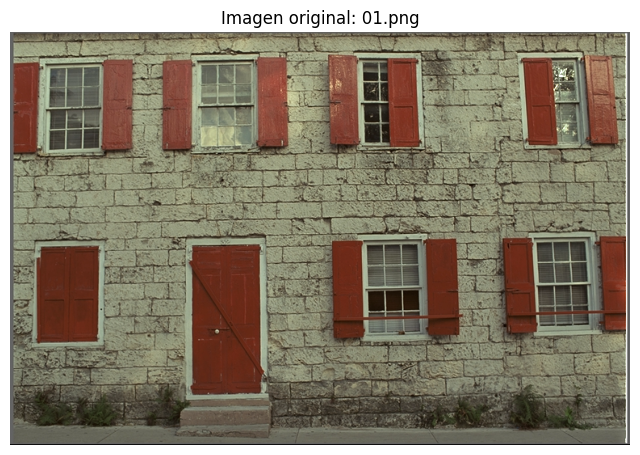

In [46]:
def load_rgb_image(path):
    """Carga una imagen RGB y la normaliza al rango [0, 1]."""
    image = Image.open(path).convert("RGB")
    return np.asarray(image, dtype=np.float64) / 255.0


# Cargar una imagen de prueba para inspeccion visual
if image_paths:
    index = 0  # Cambiar entre 0 y 23 para visualizar otra imagen

    sample_path = image_paths[index]
    sample = load_rgb_image(sample_path)

    print(f"Imagen seleccionada: {sample_path.name}")
    print(f"Dimensiones: {sample.shape}")
    print(f"Valor minimo: {sample.min():.4f}")
    print(f"Valor maximo: {sample.max():.4f}")
    print(f"Tipo de dato: {sample.dtype}")

    plt.figure(figsize=(8, 6))
    plt.imshow(sample)
    plt.title(f"Imagen original: {sample_path.name}")
    plt.axis("off")
    plt.show()

## 3. Generacion del mosaico Bayer

Una imagen RGB original puede representarse como una funcion discreta de tres canales:

$$
I(i,j) = \big(R(i,j), G(i,j), B(i,j)\big)
$$

donde $i$ representa la fila, $j$ representa la columna, y cada pixel tiene tres valores: rojo, verde y azul.

En una camara con filtro Bayer, cada pixel del sensor no mide los tres canales al mismo tiempo. En cambio, cada posicion mide solo uno de los tres colores. En esta tarea se usa el patron Bayer **RGGB**:

```text
R G R G ...
G B G B ...
R G R G ...
G B G B ...
```

Este patron tiene el doble de muestras verdes que rojas o azules, porque el ojo humano es mas sensible a variaciones de luminancia, y el canal verde aporta mucha informacion de brillo.

Matematicamente, para el patron **RGGB**, las posiciones de cada canal se definen como:

$$
M_R(i,j) =
\begin{cases}
1, & \text{si } i \text{ es par y } j \text{ es par} \\
0, & \text{en otro caso}
\end{cases}
$$

$$
M_G(i,j) =
\begin{cases}
1, & \text{si } i \text{ es par y } j \text{ es impar} \\
1, & \text{si } i \text{ es impar y } j \text{ es par} \\
0, & \text{en otro caso}
\end{cases}
$$

$$
M_B(i,j) =
\begin{cases}
1, & \text{si } i \text{ es impar y } j \text{ es impar} \\
0, & \text{en otro caso}
\end{cases}
$$

A partir de estas mascaras, el mosaico Bayer $Y(i,j)$ se obtiene seleccionando solo el canal medido en cada posicion:

$$
Y(i,j) = M_R(i,j)R(i,j) + M_G(i,j)G(i,j) + M_B(i,j)B(i,j)
$$

Por lo tanto, la salida del sensor no es una imagen RGB de tres canales, sino una imagen 2D con una sola medicion por pixel.

Visualmente, el proceso puede entenderse asi:

```text
Imagen RGB original              Filtro Bayer RGGB              Mosaico medido

[R,G,B] [R,G,B] [R,G,B]          R   G   R   G                  R   G   R   G
[R,G,B] [R,G,B] [R,G,B]    ->    G   B   G   B           ->     G   B   G   B
[R,G,B] [R,G,B] [R,G,B]          R   G   R   G                  R   G   R   G
[R,G,B] [R,G,B] [R,G,B]          G   B   G   B                  G   B   G   B
```


(512, 768, 3) 0.0 1.0


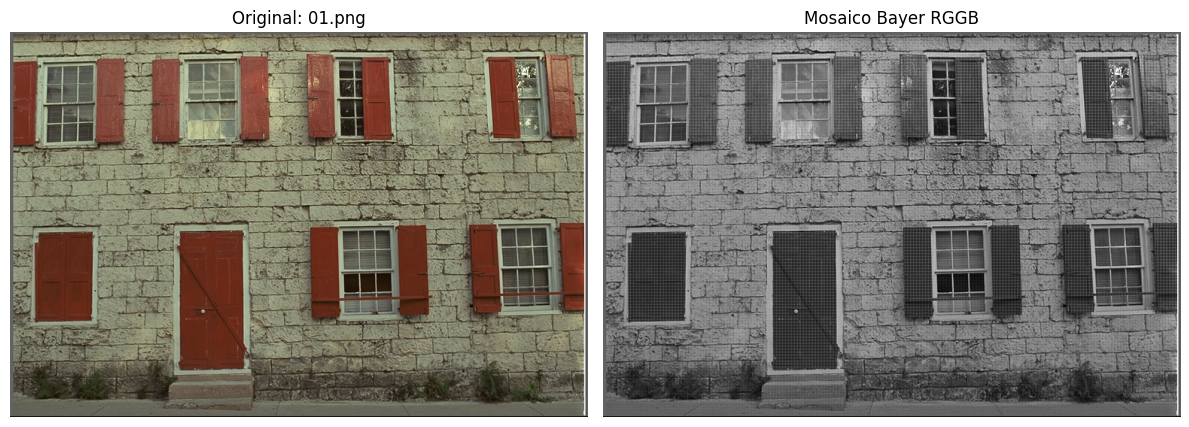

In [47]:
def bayer_masks(shape, pattern="RGGB"):
    """Retorna mascaras booleanas para los canales R, G y B segun un patron Bayer."""
    height, width = shape[:2]
    rr, cc = np.indices((height, width))

    if pattern != "RGGB":
        raise NotImplementedError("Por ahora solo se implementa el patron RGGB.")

    mask_r = (rr % 2 == 0) & (cc % 2 == 0)
    mask_g = ((rr % 2 == 0) & (cc % 2 == 1)) | ((rr % 2 == 1) & (cc % 2 == 0))
    mask_b = (rr % 2 == 1) & (cc % 2 == 1)
    return mask_r, mask_g, mask_b


def rgb_to_bayer_mosaic(image_rgb, pattern="RGGB"):
    """Genera el mosaico Bayer 2D a partir de una imagen RGB."""
    mask_r, mask_g, mask_b = bayer_masks(image_rgb.shape, pattern=pattern)
    mosaic = np.zeros(image_rgb.shape[:2], dtype=image_rgb.dtype)
    mosaic[mask_r] = image_rgb[..., 0][mask_r]
    mosaic[mask_g] = image_rgb[..., 1][mask_g]
    mosaic[mask_b] = image_rgb[..., 2][mask_b]
    return mosaic


# Visualizar imagen original y mosaico Bayer para una imagen de prueba
if image_paths:
    index = 0

    sample = load_rgb_image(image_paths[index])
    mosaic = rgb_to_bayer_mosaic(sample)

    print(sample.shape, sample.min(), sample.max())

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(sample)
    axes[0].set_title(f"Original: {image_paths[index].name}")
    axes[0].axis("off")

    axes[1].imshow(mosaic, cmap="gray")
    axes[1].set_title("Mosaico Bayer RGGB")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()


## 4. Demosaicking por interpolacion 2D

El mosaico Bayer contiene solo una medicion de color por pixel. Por lo tanto, para reconstruir una imagen RGB completa es necesario estimar los dos canales faltantes en cada posicion de la imagen. Este proceso se conoce como **demosaicking**.

Para una imagen RGB completa se busca recuperar:

$$
\hat{I}(i,j) = \big(\hat{R}(i,j), \hat{G}(i,j), \hat{B}(i,j)\big)
$$

a partir del mosaico Bayer $Y(i,j)$.

En el patron **RGGB**, cada canal tiene muestras conocidas solo en algunas posiciones:

- El canal rojo $R$ se conoce en las posiciones donde $M_R(i,j)=1$.
- El canal verde $G$ se conoce en las posiciones donde $M_G(i,j)=1$.
- El canal azul $B$ se conoce en las posiciones donde $M_B(i,j)=1$.

Para cada canal $C \in \{R,G,B\}$, se define una mascara $M_C(i,j)$ que indica donde el canal fue observado. Los valores conocidos del canal son:

$$
C_{\text{obs}}(i,j) = M_C(i,j)Y(i,j)
$$

El objetivo es estimar una version completa $\hat{C}(i,j)$ del canal, interpolando los valores faltantes sobre la grilla espacial 2D de la imagen.

En esta tarea se utiliza interpolacion 2D por canal independiente. Esto significa que cada canal se reconstruye por separado usando sus muestras conocidas:

$$
\hat{R} = \mathcal{I}(Y, M_R)
$$

$$
\hat{G} = \mathcal{I}(Y, M_G)
$$

$$
\hat{B} = \mathcal{I}(Y, M_B)
$$

donde $\mathcal{I}$ representa un operador de interpolacion 2D.

En particular, se utiliza interpolacion cubica mediante `griddata`, que estima los valores faltantes usando la posicion espacial de las muestras conocidas. Para cada canal se entregan como entrada:

- Las coordenadas conocidas $(i,j)$.
- Los valores conocidos del canal en esas coordenadas.
- Las coordenadas completas de todos los pixeles donde se desea estimar el canal.

Finalmente, los tres canales interpolados se apilan para formar la imagen RGB reconstruida:

$$
\hat{I}(i,j) =
\big(
\hat{R}(i,j),
\hat{G}(i,j),
\hat{B}(i,j)
\big)
$$

Este enfoque es simple y directo, pero tiene una limitacion importante: interpola cada canal de manera independiente. Por esto, puede producir errores en bordes, texturas finas o zonas con cambios abruptos de color, ya que no usa explicitamente la correlacion entre canales RGB.

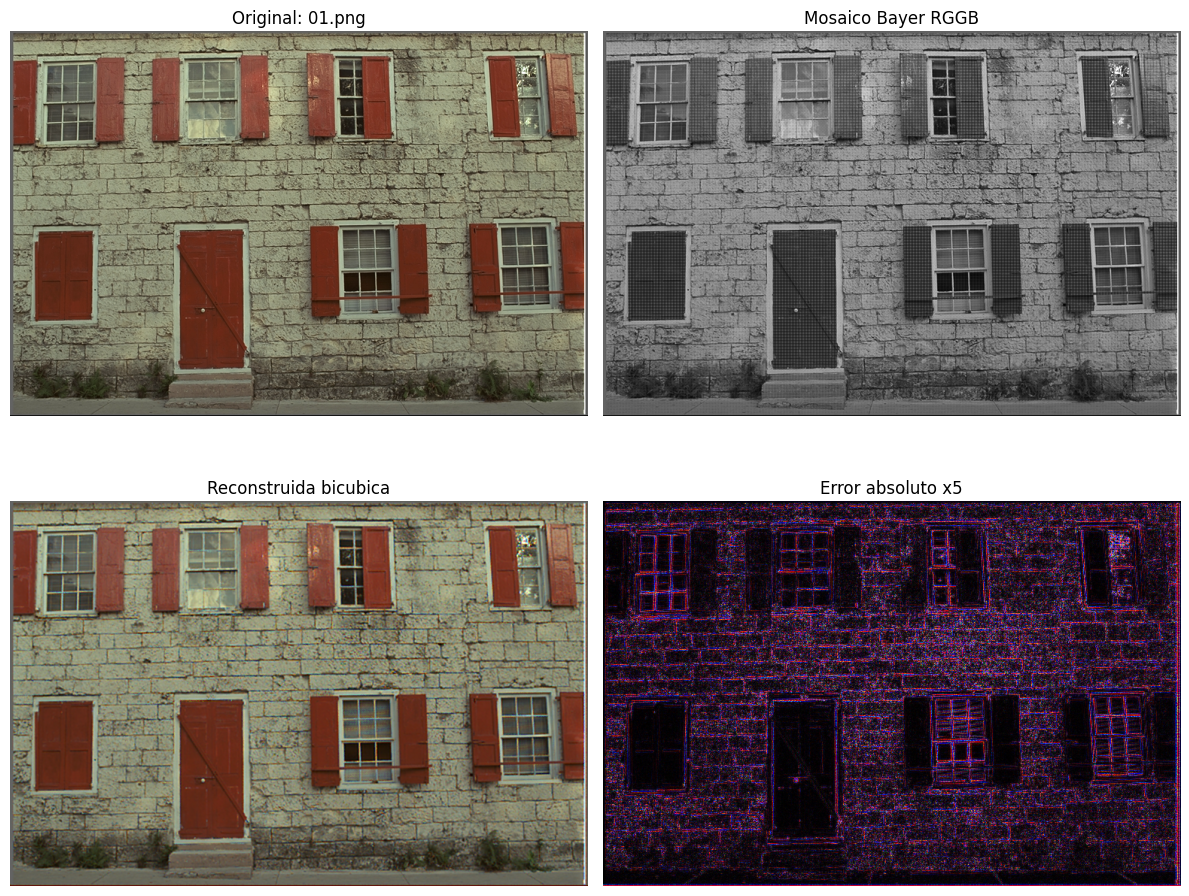

In [48]:
def interpolate_channel(mosaic, mask, method="cubic"):
    """Interpola un canal usando las muestras conocidas indicadas por mask."""
    height, width = mosaic.shape
    rr, cc = np.indices((height, width))

    known_points = np.column_stack((rr[mask], cc[mask]))
    known_values = mosaic[mask]
    all_points = np.column_stack((rr.ravel(), cc.ravel()))

    channel = griddata(
        known_points,
        known_values,
        all_points,
        method=method,
        fill_value=np.nan,
    ).reshape(height, width)

    # griddata con cubic puede dejar NaN en bordes. Se rellenan con interpolacion nearest.
    if np.isnan(channel).any():
        nearest = griddata(
            known_points,
            known_values,
            all_points,
            method="nearest",
        ).reshape(height, width)
        channel = np.where(np.isnan(channel), nearest, channel)

    return np.clip(channel, 0.0, 1.0)


def demosaick_interpolation(mosaic, pattern="RGGB", method="cubic"):
    """Reconstruye una imagen RGB desde un mosaico Bayer mediante interpolacion 2D."""
    mask_r, mask_g, mask_b = bayer_masks(mosaic.shape, pattern=pattern)

    red = interpolate_channel(mosaic, mask_r, method=method)
    green = interpolate_channel(mosaic, mask_g, method=method)
    blue = interpolate_channel(mosaic, mask_b, method=method)

    return np.stack([red, green, blue], axis=-1)


# Probar reconstruccion en una ventana 2x2
if image_paths:
    index = 0

    sample = load_rgb_image(image_paths[index])
    mosaic = rgb_to_bayer_mosaic(sample)
    reconstructed = demosaick_interpolation(mosaic, method="cubic")
    error = np.abs(sample - reconstructed)

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    axes[0, 0].imshow(sample)
    axes[0, 0].set_title(f"Original: {image_paths[index].name}")
    axes[0, 0].axis("off")

    axes[0, 1].imshow(mosaic, cmap="gray")
    axes[0, 1].set_title("Mosaico Bayer RGGB")
    axes[0, 1].axis("off")

    axes[1, 0].imshow(reconstructed)
    axes[1, 0].set_title("Reconstruida bicubica")
    axes[1, 0].axis("off")

    axes[1, 1].imshow(np.clip(error * 5, 0, 1))
    axes[1, 1].set_title("Error absoluto x5")
    axes[1, 1].axis("off")

    plt.tight_layout()
    plt.show()

## 5. Metricas de calidad

Para evaluar la calidad de la reconstruccion se compara la imagen RGB original $I$ con la imagen reconstruida $\hat{I}$. La comparacion se realiza usando tres metricas: **PSNR**, **SSIM** y **SAM**.

Estas metricas permiten analizar distintos aspectos del error de reconstruccion:

- **PSNR** mide el error cuadratico entre ambas imagenes.
- **SSIM** mide la similitud estructural percibida.
- **SAM** mide la diferencia angular entre los vectores de color RGB.

### PSNR

El **Peak Signal-to-Noise Ratio** compara la energia maxima posible de la imagen con el error cuadratico medio entre la imagen original y la reconstruida.

Primero se calcula el error cuadratico medio:

$$
MSE = \frac{1}{HWC}\sum_{i=1}^{H}\sum_{j=1}^{W}\sum_{c=1}^{C}
\left(I(i,j,c)-\hat{I}(i,j,c)\right)^2
$$

Luego, el PSNR se define como:

$$
PSNR = 10 \log_{10}\left(\frac{MAX_I^2}{MSE}\right)
$$

donde $MAX_I$ es el valor maximo posible de la imagen. Como las imagenes se normalizan al rango $[0,1]$, en este caso $MAX_I=1$.

Un valor mayor de PSNR indica una reconstruccion con menor error numerico.

### SSIM

El **Structural Similarity Index** mide la similitud estructural entre dos imagenes. A diferencia del PSNR, no solo considera el error pixel a pixel, sino tambien cambios en luminancia, contraste y estructura.

De forma general, SSIM compara dos imagenes $x$ e $y$ mediante:

$$
SSIM(x,y) =
\frac{(2\mu_x\mu_y + C_1)(2\sigma_{xy}+C_2)}
{(\mu_x^2+\mu_y^2+C_1)(\sigma_x^2+\sigma_y^2+C_2)}
$$

donde:

- $\mu_x$ y $\mu_y$ son los promedios locales.
- $\sigma_x^2$ y $\sigma_y^2$ son las varianzas locales.
- $\sigma_{xy}$ es la covarianza local.
- $C_1$ y $C_2$ son constantes de estabilizacion.

El valor de SSIM suele estar entre 0 y 1. Un valor cercano a 1 indica mayor similitud estructural con la imagen original.

### SAM

El **Spectral Angle Mapper** mide el angulo entre el vector RGB original y el vector RGB reconstruido en cada pixel.

Para un pixel en la posicion $(i,j)$, se consideran los vectores:

$$
\mathbf{v}(i,j) =
\begin{bmatrix}
R(i,j) \\
G(i,j) \\
B(i,j)
\end{bmatrix}
$$

y

$$
\hat{\mathbf{v}}(i,j) =
\begin{bmatrix}
\hat{R}(i,j) \\
\hat{G}(i,j) \\
\hat{B}(i,j)
\end{bmatrix}
$$

El angulo espectral se calcula como:

$$
SAM(i,j) =
\arccos
\left(
\frac{
\mathbf{v}(i,j) \cdot \hat{\mathbf{v}}(i,j)
}{
\|\mathbf{v}(i,j)\|_2 \|\hat{\mathbf{v}}(i,j)\|_2
}
\right)
$$

Finalmente, se reporta el promedio del angulo sobre todos los pixeles de la imagen:

$$
SAM =
\frac{1}{HW}
\sum_{i=1}^{H}
\sum_{j=1}^{W}
SAM(i,j)
$$

En esta tarea se reporta SAM en grados. Un valor menor de SAM indica que el color reconstruido tiene una direccion mas parecida al color original en el espacio RGB.


In [55]:
def compute_psnr(reference, estimate, data_range=1.0):
    """Calcula PSNR entre una imagen de referencia y una imagen estimada."""
    mse = np.mean((reference - estimate) ** 2)

    if mse == 0:
        return np.inf

    return 10 * np.log10((data_range ** 2) / mse)


def compute_ssim(reference, estimate, data_range=1.0, window_size=7):
    """
    Calcula SSIM promedio para una imagen RGB.

    Esta implementacion calcula SSIM canal por canal usando estadisticas locales
    con una ventana cuadrada y luego promedia los tres canales.
    """

    reference = reference.astype(np.float64)
    estimate = estimate.astype(np.float64)

    C1 = (0.01 * data_range) ** 2
    C2 = (0.03 * data_range) ** 2

    ssim_channels = []

    for c in range(reference.shape[-1]):
        x = reference[..., c]
        y = estimate[..., c]

        mu_x = uniform_filter(x, size=window_size)
        mu_y = uniform_filter(y, size=window_size)

        mu_x_sq = mu_x ** 2
        mu_y_sq = mu_y ** 2
        mu_xy = mu_x * mu_y

        sigma_x_sq = uniform_filter(x * x, size=window_size) - mu_x_sq
        sigma_y_sq = uniform_filter(y * y, size=window_size) - mu_y_sq
        sigma_xy = uniform_filter(x * y, size=window_size) - mu_xy

        numerator = (2 * mu_xy + C1) * (2 * sigma_xy + C2)
        denominator = (mu_x_sq + mu_y_sq + C1) * (sigma_x_sq + sigma_y_sq + C2)

        ssim_map = numerator / denominator
        ssim_channels.append(np.mean(ssim_map))

    return float(np.mean(ssim_channels))


def compute_sam(reference, estimate, eps=1e-12):
    """Calcula SAM promedio en grados entre dos imagenes RGB."""
    ref = reference.reshape(-1, reference.shape[-1])
    est = estimate.reshape(-1, estimate.shape[-1])

    dot = np.sum(ref * est, axis=1)
    ref_norm = np.linalg.norm(ref, axis=1)
    est_norm = np.linalg.norm(est, axis=1)

    cosine = dot / (ref_norm * est_norm + eps)
    cosine = np.clip(cosine, -1.0, 1.0)

    angles = np.arccos(cosine)

    return np.degrees(np.mean(angles))


def compute_metrics(reference, estimate):
    """Calcula PSNR, SSIM y SAM para una imagen reconstruida."""
    reference = np.clip(reference, 0.0, 1.0)
    estimate = np.clip(estimate, 0.0, 1.0)

    psnr = compute_psnr(reference, estimate, data_range=1.0)
    ssim = compute_ssim(reference, estimate, data_range=1.0)
    sam = compute_sam(reference, estimate)

    return {
        "PSNR": psnr,
        "SSIM": ssim,
        "SAM": sam,
    }

# Calcular metricas para una imagen de prueba
if image_paths:
    index = 0

    sample = load_rgb_image(image_paths[index])
    mosaic = rgb_to_bayer_mosaic(sample)
    reconstructed = demosaick_interpolation(mosaic, method="cubic")

    metrics = compute_metrics(sample, reconstructed)

    metrics_df = pd.DataFrame([{
        "imagen": image_paths[index].name,
        "metodo": "cubic",
        "PSNR [dB]": metrics["PSNR"],
        "SSIM": metrics["SSIM"],
        "SAM [grados]": metrics["SAM"],
    }]).round(4)

    display(metrics_df)

,imagen,metodo,PSNR [dB],SSIM,SAM [grados]
0,01.png,cubic,25.6484,0.8068,4.1911


## 6. Evaluacion completa del dataset

En esta seccion se ejecuta el flujo completo para las 24 imagenes Kodak:

1. Cargar la imagen RGB original.
2. Generar el mosaico Bayer con patron `RGGB`.
3. Reconstruir la imagen mediante demosaicking por interpolacion bicubica.
4. Calcular las metricas PSNR, SSIM y SAM.
5. Guardar los resultados en una tabla por imagen.
6. Calcular el promedio y la desviacion estandar para todo el dataset.


In [50]:
from tqdm.notebook import tqdm


def evaluate_dataset(image_paths, method="cubic", pattern="RGGB"):
    """Evalua el proceso completo de demosaicking para todas las imagenes."""
    rows = []

    for index, path in enumerate(tqdm(image_paths, desc="Evaluando imagenes Kodak")):
        original = load_rgb_image(path)
        mosaic = rgb_to_bayer_mosaic(original, pattern=pattern)
        reconstructed = demosaick_interpolation(mosaic, pattern=pattern, method=method)
        metrics = compute_metrics(original, reconstructed)

        rows.append({
            "indice": index,
            "imagen": path.name,
            "patron_bayer": pattern,
            "metodo": method,
            "PSNR [dB]": metrics["PSNR"],
            "SSIM": metrics["SSIM"],
            "SAM [grados]": metrics["SAM"],
        })

    return pd.DataFrame(rows)


# Evaluar las 24 imagenes Kodak
results = evaluate_dataset(
    image_paths=image_paths,
    method="cubic",
    pattern="RGGB",
)

# Tabla de metricas por imagen, redondeada para presentacion
results_rounded = results.copy()
results_rounded["PSNR [dB]"] = results_rounded["PSNR [dB]"].round(4)
results_rounded["SSIM"] = results_rounded["SSIM"].round(4)
results_rounded["SAM [grados]"] = results_rounded["SAM [grados]"].round(4)

display(results_rounded)


Evaluando imagenes Kodak:   0%|          | 0/24 [00:00<?, ?it/s]

,indice,imagen,patron_bayer,metodo,PSNR [dB],SSIM,SAM [grados]
0,0,01.png,RGGB,cubic,25.6484,0.8068,4.1911
1,1,02.png,RGGB,cubic,31.7725,0.8888,1.8831
2,2,03.png,RGGB,cubic,32.8036,0.9268,1.4083
3,3,04.png,RGGB,cubic,32.5873,0.9126,1.7210
4,4,05.png,RGGB,cubic,26.3705,0.8867,4.8910
5,5,06.png,RGGB,cubic,26.9158,0.8412,3.0628
6,6,07.png,RGGB,cubic,32.7276,0.9546,1.6061
7,7,08.png,RGGB,cubic,23.2294,0.8251,4.8424
8,8,09.png,RGGB,cubic,31.7936,0.9155,1.5338
9,9,10.png,RGGB,cubic,31.5631,0.9170,1.5836


In [51]:
# Promedio y desviacion estandar para todo el dataset
summary = results[["PSNR [dB]", "SSIM", "SAM [grados]"]].agg(["mean", "std"])
summary_rounded = summary.round(4)

display(summary_rounded)

# Guardar resultados en archivos CSV
output_dir = Path("resultados")
output_dir.mkdir(exist_ok=True)

results_rounded.to_csv(output_dir / "metricas_por_imagen.csv", index=False)
summary_rounded.to_csv(output_dir / "metricas_resumen.csv")

print(f"Resultados guardados en: {output_dir}")


,PSNR [dB],SSIM,SAM [grados]
mean,29.3063,0.8857,2.748
std,2.9898,0.0425,1.231


Resultados guardados en: resultados


## 7. Visualizacion de resultados

Para inspeccionar cualitativamente el resultado, se muestra una imagen del dataset en una grilla 2 x 2:

- Imagen RGB original.
- Mosaico Bayer `RGGB`.
- Imagen reconstruida con interpolacion bicubica.
- Mapa de error absoluto amplificado para facilitar la visualizacion.


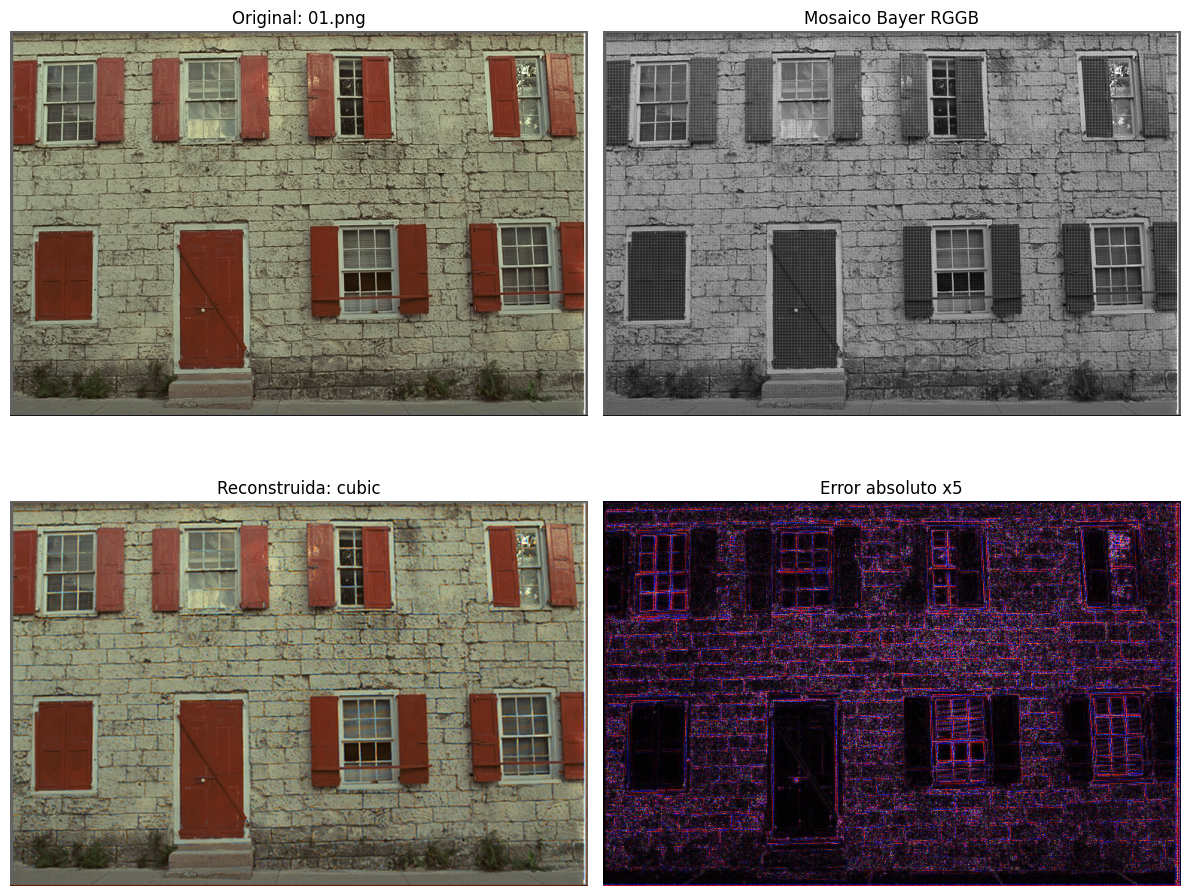

,imagen,metodo,PSNR [dB],SSIM,SAM [grados]
0,01.png,cubic,25.6484,0.8068,4.1911


In [52]:
def visualize_reconstruction(path, method="cubic", pattern="RGGB", error_scale=5):
    """Muestra original, mosaico Bayer, reconstruccion y error absoluto en una grilla 2x2."""
    original = load_rgb_image(path)
    mosaic = rgb_to_bayer_mosaic(original, pattern=pattern)
    reconstructed = demosaick_interpolation(mosaic, pattern=pattern, method=method)
    error = np.abs(original - reconstructed)
    metrics = compute_metrics(original, reconstructed)

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    axes[0, 0].imshow(original)
    axes[0, 0].set_title(f"Original: {path.name}")
    axes[0, 0].axis("off")

    axes[0, 1].imshow(mosaic, cmap="gray")
    axes[0, 1].set_title(f"Mosaico Bayer {pattern}")
    axes[0, 1].axis("off")

    axes[1, 0].imshow(reconstructed)
    axes[1, 0].set_title(f"Reconstruida: {method}")
    axes[1, 0].axis("off")

    axes[1, 1].imshow(np.clip(error * error_scale, 0, 1))
    axes[1, 1].set_title(f"Error absoluto x{error_scale}")
    axes[1, 1].axis("off")

    plt.tight_layout()
    plt.show()

    metrics_df = pd.DataFrame([{
        "imagen": path.name,
        "metodo": method,
        "PSNR [dB]": metrics["PSNR"],
        "SSIM": metrics["SSIM"],
        "SAM [grados]": metrics["SAM"],
    }]).round(4)

    display(metrics_df)
    return metrics


# Cambiar este indice para visualizar otras imagenes del dataset: 0 a 23
if image_paths:
    index = 0
    visualize_reconstruction(image_paths[index], method="cubic", pattern="RGGB")


**Conclusiones**:

En esta tarea se implemento un sistema basico de fotografia computacional para simular la captura de una imagen RGB mediante un filtro Bayer con patron `RGGB`. A partir del mosaico generado, se reconstruyeron los tres canales de color usando demosaicking por interpolacion cubica 2D aplicada de manera independiente a los canales rojo, verde y azul.

Para el dataset Kodak completo se obtuvo un PSNR promedio de **29.3063 dB**, un SSIM promedio de **0.8862** y un SAM promedio de **2.748 grados**. La desviacion estandar fue de **2.9898 dB** para PSNR, **0.0430** para SSIM y **1.231 grados** para SAM.

Estos valores indican que la interpolacion cubica logra una reconstruccion razonable de las imagenes RGB a partir del mosaico Bayer. El PSNR promedio cercano a 30 dB muestra que el error numerico es moderado, mientras que el SSIM promedio cercano a 0.9 indica que gran parte de la estructura visual de las imagenes originales se conserva. Por otro lado, el SAM promedio bajo sugiere que, en general, la direccion de los vectores de color RGB reconstruidos es similar a la original.

La mejor reconstruccion segun PSNR fue `23.png`, con **33.8756 dB**, mientras que la peor fue `08.png`, con **23.2294 dB**. Esta diferencia muestra que el desempeño del metodo depende del contenido de la imagen. Las imagenes con regiones suaves o cambios graduales de color son mas faciles de interpolar, mientras que las imagenes con texturas finas, bordes marcados o variaciones abruptas de color producen mayores errores.

Como limitacion principal, el metodo utilizado interpola cada canal de forma independiente, sin aprovechar directamente la correlacion existente entre los canales RGB. Por esta razon, pueden aparecer errores en bordes y detalles de alta frecuencia. Metodos de demosaicking mas avanzados podrian mejorar la reconstruccion incorporando informacion conjunta entre canales o estrategias adaptativas segun la direccion de los bordes.

## Bonus: algoritmo ICASSP 2004

Implementar y evaluar el algoritmo descrito en el articulo:

<https://web.stanford.edu/class/ee367/reading/Demosaicing_ICASSP04.pdf>

En esta seccion se debe explicar brevemente la idea principal del metodo, implementar la reconstruccion y compararla contra la interpolacion bicubica usando las mismas metricas.

In [57]:
def demosaick_malvar2004(mosaic, pattern="RGGB"):
    """
    Demosaicking Malvar, He y Cutler (2004).

    Paper:
    High-Quality Linear Interpolation for Demosaicing of
    Bayer-Patterned Color Images.

    Esta implementacion usa filtros lineales 5x5 para reconstruir
    los canales RGB desde un mosaico Bayer.
    """
    if pattern != "RGGB":
        raise NotImplementedError("Esta version implementa solo el patron RGGB.")

    mosaic = mosaic.astype(np.float64)

    mask_r, mask_g, mask_b = bayer_masks(mosaic.shape, pattern=pattern)

    # Filtro para estimar G en posiciones R o B
    kernel_g_at_rb = np.array([
        [0,  0, -1,  0,  0],
        [0,  0,  2,  0,  0],
        [-1, 2,  4,  2, -1],
        [0,  0,  2,  0,  0],
        [0,  0, -1,  0,  0],
    ], dtype=np.float64) / 8

    # Filtro para estimar R en G de fila R / B en G de fila B
    kernel_rb_at_g_1 = np.array([
        [0,   0, 0.5, 0,   0],
        [0,  -1, 0,  -1,   0],
        [-1,  4, 5,   4,  -1],
        [0,  -1, 0,  -1,   0],
        [0,   0, 0.5, 0,   0],
    ], dtype=np.float64) / 8

    # Filtro transpuesto para la otra orientacion
    kernel_rb_at_g_2 = kernel_rb_at_g_1.T

    # Filtro para estimar R en B y B en R
    kernel_rb_at_br = np.array([
        [0,    0, -1.5, 0,    0],
        [0,    2,  0,   2,    0],
        [-1.5, 0,  6,   0,   -1.5],
        [0,    2,  0,   2,    0],
        [0,    0, -1.5, 0,    0],
    ], dtype=np.float64) / 8

    # Inicializar canales con los valores conocidos
    red = mosaic * mask_r
    green = mosaic * mask_g
    blue = mosaic * mask_b

    # Reconstruir G en posiciones R y B
    green_interp = convolve(mosaic, kernel_g_at_rb, mode="mirror")
    green = np.where(mask_r | mask_b, green_interp, green)

    # Convoluciones para R y B faltantes
    rb_interp_1 = convolve(mosaic, kernel_rb_at_g_1, mode="mirror")
    rb_interp_2 = convolve(mosaic, kernel_rb_at_g_2, mode="mirror")
    rb_interp_3 = convolve(mosaic, kernel_rb_at_br, mode="mirror")

    height, width = mosaic.shape
    rows, cols = np.indices((height, width))

    red_row = rows % 2 == 0
    blue_row = rows % 2 == 1
    red_col = cols % 2 == 0
    blue_col = cols % 2 == 1

    # Para patron RGGB:
    # R esta en fila par, columna par.
    # B esta en fila impar, columna impar.

    # R en pixeles verdes
    red = np.where(red_row & blue_col, rb_interp_1, red)
    red = np.where(blue_row & red_col, rb_interp_2, red)

    # B en pixeles verdes
    blue = np.where(blue_row & red_col, rb_interp_1, blue)
    blue = np.where(red_row & blue_col, rb_interp_2, blue)

    # R en pixeles azules y B en pixeles rojos
    red = np.where(mask_b, rb_interp_3, red)
    blue = np.where(mask_r, rb_interp_3, blue)

    reconstructed = np.stack([red, green, blue], axis=-1)

    return np.clip(reconstructed, 0.0, 1.0)

In [59]:
def evaluate_dataset_malvar(image_paths, pattern="RGGB"):
    rows = []

    for index, path in enumerate(tqdm(image_paths, desc="Evaluando Malvar 2004")):
        original = load_rgb_image(path)
        mosaic = rgb_to_bayer_mosaic(original, pattern=pattern)
        reconstructed = demosaick_malvar2004(mosaic, pattern=pattern)
        metrics = compute_metrics(original, reconstructed)

        rows.append({
            "indice": index,
            "imagen": path.name,
            "patron_bayer": pattern,
            "metodo": "Malvar2004",
            "PSNR [dB]": metrics["PSNR"],
            "SSIM": metrics["SSIM"],
            "SAM [grados]": metrics["SAM"],
        })

    return pd.DataFrame(rows)


malvar_results = evaluate_dataset_malvar(image_paths)

malvar_results_rounded = malvar_results.copy()
malvar_results_rounded["PSNR [dB]"] = malvar_results_rounded["PSNR [dB]"].round(4)
malvar_results_rounded["SSIM"] = malvar_results_rounded["SSIM"].round(4)
malvar_results_rounded["SAM [grados]"] = malvar_results_rounded["SAM [grados]"].round(4)

display(malvar_results_rounded)

Evaluando Malvar 2004:   0%|          | 0/24 [00:00<?, ?it/s]

,indice,imagen,patron_bayer,metodo,PSNR [dB],SSIM,SAM [grados]
0,0,01.png,RGGB,Malvar2004,31.6608,0.9553,2.4269
1,1,02.png,RGGB,Malvar2004,35.8906,0.9617,1.2856
2,2,03.png,RGGB,Malvar2004,37.1981,0.9764,0.9568
3,3,04.png,RGGB,Malvar2004,37.4597,0.9738,1.1332
4,4,05.png,RGGB,Malvar2004,32.8102,0.9746,2.9792
5,5,06.png,RGGB,Malvar2004,32.5555,0.9597,1.8109
6,6,07.png,RGGB,Malvar2004,37.6348,0.9835,1.1268
7,7,08.png,RGGB,Malvar2004,29.1082,0.9560,2.9363
8,8,09.png,RGGB,Malvar2004,37.2758,0.9731,1.0336
9,9,10.png,RGGB,Malvar2004,37.7716,0.9754,1.0147


In [60]:
comparison = pd.concat([results, malvar_results], ignore_index=True)

comparison_summary = comparison.groupby("metodo")[[
    "PSNR [dB]",
    "SSIM",
    "SAM [grados]"
]].agg(["mean", "std"]).round(4)

display(comparison_summary)

PSNR [dB]            SSIM         SAM [grados]        
                mean     std    mean     std         mean     std
metodo                                                           
Malvar2004   34.6940  2.5837  0.9681  0.0082       1.7049  0.6901
cubic        29.3063  2.9898  0.8857  0.0425       2.7480  1.2310

In [61]:
psnr_gain = (
    comparison_summary.loc["Malvar2004", ("PSNR [dB]", "mean")]
    - comparison_summary.loc["cubic", ("PSNR [dB]", "mean")]
)

ssim_gain = (
    comparison_summary.loc["Malvar2004", ("SSIM", "mean")]
    - comparison_summary.loc["cubic", ("SSIM", "mean")]
)

sam_reduction = (
    comparison_summary.loc["cubic", ("SAM [grados]", "mean")]
    - comparison_summary.loc["Malvar2004", ("SAM [grados]", "mean")]
)

print(f"Mejora PSNR: {psnr_gain:.4f} dB")
print(f"Mejora SSIM: {ssim_gain:.4f}")
print(f"Reduccion SAM: {sam_reduction:.4f} grados")

Mejora PSNR: 5.3877 dB
Mejora SSIM: 0.0824
Reduccion SAM: 1.0431 grados


**Conclusiones**:

Al comparar ambos métodos, el algoritmo de Malvar, He y Cutler (2004) obtuvo mejores resultados que la interpolación cúbica independiente en todas las métricas evaluadas. El PSNR promedio aumentó de **29.3063 dB** a **34.6940 dB**, lo que representa una mejora aproximada de **5.39 dB**. Además, el SSIM promedio subió de **0.8857** a **0.9681**, indicando una mayor conservación de la estructura visual de las imágenes originales.

En términos de SAM, el valor promedio disminuyó de **2.7480 grados** a **1.7049 grados**, lo que indica que los vectores de color RGB reconstruidos por Malvar2004 tienen una dirección más cercana a los colores originales. También se observa una menor desviación estándar en SSIM y SAM, lo que sugiere que el método es más consistente a lo largo del dataset.

Esta mejora se debe a que Malvar2004 no interpola cada canal de forma completamente independiente, sino que utiliza filtros lineales 5x5 con corrección de gradiente. Estos filtros incorporan información de la estructura local de la imagen y aprovechan mejor la correlación entre los canales de color, reduciendo errores en bordes, texturas y cambios abruptos de intensidad.